# MediCheck-GPT: run the full flow on Colab
Runtime → Change runtime type → **T4 GPU**. Run top to bottom. Every number in the README comes from this notebook's output.

## 0. Setup: GPU, code, data

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv   # confirm the T4 is attached

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
from google.colab import drive
drive.mount('/content/drive')                     # the raw CMS file lives in my Drive
ROOT = '/content/drive/MyDrive/build-transformer'   # same folder as 01_data.ipynb

Mounted at /content/drive


In [3]:
!git clone https://github.com/cece15/medicheck-gpt.git /content/medicheck-gpt
%cd /content/medicheck-gpt
!pip install -q -r requirements.txt
# data and checkpoints live in Drive, so a Colab disconnect loses nothing: rerun from the cell that stopped
!mkdir -p "$ROOT/medicheck/data" "$ROOT/medicheck/checkpoints"
!ln -sfn "$ROOT/medicheck/data" data && ln -sfn "$ROOT/medicheck/checkpoints" checkpoints && ls -l

Cloning into '/content/medicheck-gpt'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 50 (delta 25), reused 44 (delta 19), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 36.40 KiB | 4.04 MiB/s, done.
Resolving deltas: 100% (25/25), done.
/content/medicheck-gpt
total 52
lrwxrwxrwx 1 root root    62 Nov 14 18:17 checkpoints -> /content/drive/MyDrive/build-transformer/medicheck/checkpoints
lrwxrwxrwx 1 root root    55 Nov 14 18:17 data -> /content/drive/MyDrive/build-transformer/medicheck/data
-rwxr-xr-x 1 root root 12612 Nov 14 18:17 gpt.py
drwxr-xr-x 2 root root  4096 Nov 14 18:17 notebooks
-rw-r--r-- 1 root root  9780 Nov 14 18:17 README.md
-rw-r--r-- 1 root root   140 Nov 14 18:17 requirements.txt
drwxr-xr-x 2 root root  4096 Nov 14 18:17 src
-rw-r--r-- 1 root root  7942 Nov 14 18:17 WALKTHROUGH.md


## 1. Data: CSV → one sentence per row → split by hospital

In [4]:
!python gpt.py --input "$ROOT/data/raw/MUP_INP_RY26_P03_V10_DY24_PrvSvc.CSV" --prepare data/processed
!head -c 600 data/processed/train.txt

device: cuda
{
 "train": {
  "hospitals": 160,
  "records": 7891,
  "chars": 1598112
 },
 "val": {
  "hospitals": 20,
  "records": 987,
  "chars": 198311
 },
 "test": {
  "hospitals": 20,
  "records": 762,
  "chars": 152994
 }
}

Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 291 (HEART FAILURE AND SHOCK WITH MCC) for 20 discharges: covered charges $19134, total payment $9134, Medicare payment $7828.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 872 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITHOUT MCC) for 21 discharges: covered charges $19285, total payment $8101, Medicare p

## 2. Baseline: bigram (one character of memory)

In [5]:
!python gpt.py --input data/processed --train checkpoints/bigram.pth --model bigram --context_size 8 --lr 1e-2 --steps 3000

device: cuda
bigram: 0.01M parameters | vocab 77 | train 1,598,112 chars | val 198,311 chars
step      0 | train 4.8428 | val 4.8593 | val_perplexity 128.937 | 0s
step    500 | train 2.4266 | val 2.4350 | val_perplexity 11.416 | 2s
step   1000 | train 2.2191 | val 2.2231 | val_perplexity 9.236 | 3s
step   1500 | train 2.1804 | val 2.1960 | val_perplexity 8.989 | 4s
step   2000 | train 2.1307 | val 2.1515 | val_perplexity 8.598 | 5s
step   2500 | train 2.1700 | val 2.1600 | val_perplexity 8.671 | 6s
step   2999 | train 2.1324 | val 2.1858 | val_perplexity 8.898 | 8s
best val loss 2.1515 saved to checkpoints/bigram.pth


## 3. Transformer: 4 layers, 4 heads, 128-dim, context 271 (one full record)
Cosine LR with warmup, weight decay, early stopping. First run (3 Nov) overfit after ~1,500 steps, so these guards matter.

In [6]:
!python gpt.py --input data/processed --train checkpoints/gpt.pth --steps 10000 --eval_every 500 --patience 4

device: cuda
gpt: 0.85M parameters | vocab 77 | train 1,598,112 chars | val 198,311 chars
step      0 | train 4.4752 | val 4.4695 | val_perplexity 87.314 | gen_medicare_le_total 0.000 | 14s
step    500 | train 0.9039 | val 1.0081 | val_perplexity 2.740 | gen_medicare_le_total 0.125 | 51s
step   1000 | train 0.4762 | val 0.7157 | val_perplexity 2.046 | gen_medicare_le_total 0.125 | 90s
step   1500 | train 0.3578 | val 0.6575 | val_perplexity 1.930 | gen_medicare_le_total 0.375 | 128s
step   2000 | train 0.3167 | val 0.6716 | val_perplexity 1.957 | gen_medicare_le_total 0.250 | 169s
step   2500 | train 0.2966 | val 0.6746 | val_perplexity 1.963 | gen_medicare_le_total 0.500 | 210s
step   3000 | train 0.2834 | val 0.6541 | val_perplexity 1.923 | gen_medicare_le_total 0.500 | 250s
step   3500 | train 0.2782 | val 0.6620 | val_perplexity 1.939 | gen_medicare_le_total 0.500 | 290s
step   4000 | train 0.2574 | val 0.6524 | val_perplexity 1.920 | gen_medicare_le_total 0.375 | 329s
step   4500 

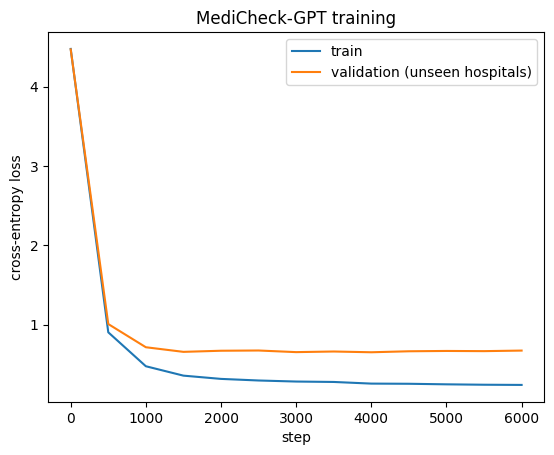

In [7]:
# Loss curve for the slides
import json, matplotlib.pyplot as plt
h = json.load(open('checkpoints/gpt_history.json'))
plt.plot([r['step'] for r in h], [r['train'] for r in h], label='train')
plt.plot([r['step'] for r in h], [r['val'] for r in h], label='validation (unseen hospitals)')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.title('MediCheck-GPT training')
plt.savefig('checkpoints/loss_curve.png', dpi=200, bbox_inches='tight'); plt.show()

## 3a. Hyperparameter comparison (Week 7: fine-tuning and hyperparameter tuning)
Same data, same seed, same early stopping. Only the model size and dropout change. About 15 minutes.

In [8]:
# smaller and larger than the base model (base = 4 layers, 4 heads, 128-dim, already trained above)
!python gpt.py --input data/processed --train checkpoints/gpt_small.pth --n_layer 2 --n_head 2 --n_embd 64 --steps 6000
!python gpt.py --input data/processed --train checkpoints/gpt_large.pth --n_layer 6 --n_head 6 --n_embd 192 --dropout 0.2 --steps 6000

device: cuda
gpt: 0.13M parameters | vocab 77 | train 1,598,112 chars | val 198,311 chars
step      0 | train 4.5941 | val 4.5881 | val_perplexity 98.305 | gen_medicare_le_total 0.000 | 4s
step    500 | train 1.4964 | val 1.5318 | val_perplexity 4.626 | gen_medicare_le_total 0.000 | 14s
step   1000 | train 1.0703 | val 1.1483 | val_perplexity 3.153 | gen_medicare_le_total 0.000 | 24s
step   1500 | train 0.8775 | val 1.0035 | val_perplexity 2.728 | gen_medicare_le_total 0.000 | 34s
step   2000 | train 0.7326 | val 0.8932 | val_perplexity 2.443 | gen_medicare_le_total 0.000 | 44s
step   2500 | train 0.6429 | val 0.8360 | val_perplexity 2.307 | gen_medicare_le_total 0.000 | 55s
step   3000 | train 0.5803 | val 0.7809 | val_perplexity 2.183 | gen_medicare_le_total 0.000 | 65s
step   3500 | train 0.5422 | val 0.7502 | val_perplexity 2.118 | gen_medicare_le_total 0.000 | 75s
step   4000 | train 0.5099 | val 0.7488 | val_perplexity 2.114 | gen_medicare_le_total 0.000 | 84s
step   4500 | train

In [9]:
# one table for the slides: which size generalizes best to unseen hospitals?
import math, torch, pandas as pd
from src.model import build, count_params
rows = []
for name in ['gpt_small', 'gpt', 'gpt_large']:
    ck = torch.load(f'checkpoints/{name}.pth', map_location='cpu')
    best = min(ck['history'], key=lambda r: r['val'])            # the checkpoint holds the best evaluation
    rows.append({'model': name, **{k: ck['config'][k] for k in ['n_layer', 'n_head', 'n_embd', 'dropout']},
                 'parameters': count_params(build(ck['kind'], **ck['config'])),
                 'best_step': best['step'], 'best_val_loss': round(best['val'], 4),
                 'val_perplexity': round(math.exp(best['val']), 3), 'seconds': best['seconds']})
pd.DataFrame(rows)

,model,n_layer,n_head,n_embd,dropout,parameters,best_step,best_val_loss,val_perplexity,seconds
0,gpt_small,2,2,64,0.1,126989,5000,0.7157,2.046,105
1,gpt,4,4,128,0.1,846285,4000,0.6524,1.920,329
2,gpt_large,6,6,192,0.2,2747789,1500,0.6205,1.860,298


## 3b. Kacper's recommendation: an LLM teacher writes plain-English descriptions
Python computes every number; the LLM only phrases. Any sentence with a number not in the record is rejected. About 20–30 minutes on a T4.

In [ ]:
import os
if not os.path.exists('data/described/test.txt'):          # the teacher is the slow step: never run it twice
    !python gpt.py --input data/processed --teacher data/described --limit 3000
print(open('data/described/teacher_report.json').read())
!head -c 900 data/described/train.txt

device: cuda
config.json: 100% 660/660 [00:00<00:00, 3.09MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 22.2MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 71.5MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 131MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 160MB/s]

model.safetensors: downloading bytes:   0% 0.00/3.09G [00:00<?, ?B/s]
model.safetensors: downloading bytes:   2% 65.5M/3.09G [00:01<00:36, 83.8MB/s, 5.23MB/s  ]
model.safetensors: downloading bytes:   6% 178M/3.09G [00:02<00:18, 154MB/s, 13.1MB/s  ]
model.safetensors: downloading bytes:   7% 202M/3.09G [00:03<00:20, 139MB/s, 16.2MB/s  ]
model.safetensors: downloading bytes:  10% 298M/3.09G [00:03<00:13, 208MB/s, 23.2MB/s  ]
model.safetensors: reconstructing file:   0% 5.93M/3.09G [00:03<25:12, 2.04MB/s,  462kB/s  ]
model.safetensors: reconstructing file:   3% 78.2M/3.09G [00:03<00:49, 60.2MB/s,  507kB/s  ]
model.safetensors: reconstructing file:   5% 156M/3.09G [00:03<00:21, 134MB/s, 7.09MB/s  ]  
mode

## 3c. Student: train a small GPT to explain records the way the teacher does
Metrics (perplexity, ROUGE-L on validation) print at every evaluation, from inside the training loop.

In [ ]:
!python gpt.py --input data/described --train checkpoints/explain.pth --steps 10000 --eval_every 500 --patience 4

In [ ]:
!python gpt.py --eval checkpoints/explain.pth --prompt "$(sed -n 2p data/processed/test.txt)"

## 4. Generate

In [ ]:
!python gpt.py --eval checkpoints/gpt.pth --n 3
!python gpt.py --eval checkpoints/gpt.pth --n 2 --prompt "Trinity Health Livonia Hospital in Livonia, MI billed DRG "

## 5. Evaluate: perplexity, token accuracy, ROUGE-L (+ BLEU, BERTScore), record validity

In [ ]:
!python gpt.py --input data/processed --evaluate checkpoints/bigram.pth
!python gpt.py --input data/processed --evaluate checkpoints/gpt.pth --hf_metrics
!python gpt.py --input data/described --evaluate checkpoints/explain.pth --hf_metrics

## 6. Flag silent errors: plant four error types in unseen hospitals' records, measure ROC AUC

In [ ]:
!python gpt.py --input data/processed --flag checkpoints/bigram.pth
!python gpt.py --input data/processed --flag checkpoints/gpt.pth

## 7. Results are already in Drive (`build-transformer/medicheck/`)

In [ ]:
!ls -lh checkpoints/ data/described/

## Live demo (Tuesday)
`!python gpt.py --eval checkpoints/explain.pth --interactive`  (paste a record, get the plain-English sentence)

`!python gpt.py --flag checkpoints/gpt.pth --flag_file suspicious.txt`  (rank records, most surprising first)